# Task 4 - Explainable Fuzzy Classifier

This notebook uses fuzzy classifier (from pyFUME) with 6 geometric features using dlib landmarks.

### 1. Setup - imports/paths/defaults

In [63]:
import pickle
from pathlib import Path
import numpy as np
import pandas as pd

KDEF_DIR = Path('../data/KDEF')
MODELS_DIR = Path('../models/phase_c')
MODELS_DIR.mkdir(parents=True, exist_ok=True)
CODES = {'AF': 'afraid', 'AN': 'angry', 'DI': 'disgust', 'HA': 'happy',
         'NE': 'neutral', 'SA': 'sad', 'SU': 'surprise'}
FEATURES = ['mouth_open', 'mouth_width', 'eye_open', 'brow_height', 'smile_ratio', 'lip_raise']

np.random.seed(42) # for reproducibility

### 2. Apply split and change file name into columns in df

In [64]:
rows = []
for p in KDEF_DIR.rglob('*.JPG'):
    name = p.name.split('.')[0]
    if len(name) == 7 and name.endswith('S') and name[4:6] in CODES:
        rows.append({'path': str(p), 
                     'subject': name[1:4], 
                     'emotion': CODES[name[4:6]]}
        )
df = pd.DataFrame(rows)

with open('../auxFiles/kdef_subject_split.pkl', 'rb') as f:
    split = pickle.load(f)

train_subjects = list(split['train_subjects'])
df['set'] = ['train' if s in train_subjects else 'test' for s in df['subject']]

print(df['set'].value_counts())

train    784
test     196
Name: set, dtype: int64


### 3. Landmarks from dlib

In [65]:
import dlib

frontal_detector = dlib.get_frontal_face_detector()
predictor = dlib.shape_predictor('../faceAndLandmarkModels/shape_predictor_68_face_landmarks.dat')

def get_landmarks(path):
    img = dlib.load_grayscale_image(path)
    face = max(frontal_detector(img, 0), key=lambda r: r.area())
    shape = predictor(img, face)
    return [(pt.x, pt.y) for pt in shape.parts()]

landmarks = [get_landmarks(p) for p in df['path']]

### 4. Features

We have chosen those geometric features:
- mouth open
- mouth width
- eye opening
- eyebrow height
- smile ratio
- lip raise

In [66]:
def dist(a, b):
    return np.linalg.norm(a-b)

def geometric_features(l):
    left_eye = l[36:42].mean(axis=0)
    right_eye = l[42:48].mean(axis=0)
    eye_dist = dist(left_eye, right_eye) #helper for the more complciated features

    mouth_open = dist(l[62], l[66]) / eye_dist                   

    mouth_width = dist(l[48], l[54]) / eye_dist                   

    eye_open = (dist(l[37], l[41]) + dist(l[38], l[40]) + dist(l[43], l[47]) + dist(l[44], l[46])) / 4 / eye_dist

    brow_height = ((left_eye[1] + right_eye[1]) / 2 - l[17:27, 1].mean()) / eye_dist

    smile_ratio = ((l[62, 1] + l[66, 1]) / 2 - (l[48, 1] + l[54, 1]) / 2) / dist(l[48], l[54])
    
    lip_raise = dist(l[33], l[51]) / eye_dist

    return [mouth_open, mouth_width, eye_open, brow_height, smile_ratio, lip_raise]

In [67]:
from features import KDEF_TO_FER

df_feat = pd.DataFrame([geometric_features(l) for l in np.array(landmarks)], columns=FEATURES)
df_feat['label'] = df['emotion'].map(KDEF_TO_FER)
df_feat['set'] = df['set']

X_train, y_train = df_feat[df_feat['set'] == 'train'][FEATURES].values, df_feat[df_feat['set'] == 'train']['label'].values
X_test, y_test = df_feat[df_feat['set'] == 'test'][FEATURES].values, df_feat[df_feat['set'] == 'test']['label'].values

df_feat.groupby('label')[FEATURES].mean().round(3)

,mouth_open,mouth_width,eye_open,brow_height,smile_ratio,lip_raise
label,,,,,,
0,0.063,0.798,0.120,0.199,0.017,0.235
1,0.114,0.848,0.090,0.209,0.017,0.181
2,0.143,0.834,0.159,0.307,0.008,0.223
3,0.168,1.109,0.109,0.281,0.116,0.174
4,0.017,0.850,0.125,0.287,-0.016,0.228
5,0.227,0.753,0.178,0.369,0.013,0.237
6,0.011,0.826,0.139,0.286,-0.010,0.245


### 4. Train the fuzzy model

In [68]:
from pyfume import *
import skfuzzy as fuzz

nr_clus = 3

def build_fuzzy_model(x_train, y_train):
    # Cluster with FCM
    cl = Clusterer(x_train=x_train, y_train=y_train, nr_clus=nr_clus)
    cluster_centers, partition_matrix, _ = cl.cluster(method="fcm")

    # Estimate the membership functions
    ae = AntecedentEstimator(x_train=x_train, partition_matrix=partition_matrix)
    antecedent_parameters = ae.determineMF()

    # Calculate firing strengths
    fsc = FireStrengthCalculator(antecedent_parameters=antecedent_parameters,
                                 nr_clus=nr_clus, variable_names=FEATURES)
    firing_strengths = fsc.calculate_fire_strength(data=x_train)

    # Estimate consequent parameters
    ce = ConsequentEstimator(x_train=x_train, y_train=y_train, firing_strengths=firing_strengths)
    consequent_parameters = ce.suglms()

    # Build Takagi-Sugeno model
    simpbuilder = SugenoFISBuilder(antecedent_sets=antecedent_parameters,
                                   consequent_parameters=consequent_parameters,
                                   variable_names=FEATURES, save_simpful_code=False)
    return simpbuilder.get_model(), antecedent_parameters, consequent_parameters

# one-vs-rest: one model per emotion
models, antecedents, consequents = {}, {}, {}
for e in range(7):
    y_train_binary = (y_train == e).astype(float)
    models[e], antecedents[e], consequents[e] = build_fuzzy_model(X_train, y_train_binary)

['mouth_open', 'mouth_width', 'eye_open', 'brow_height', 'smile_ratio', 'lip_raise']
 * Detected 3 rules / clusters
 * Detected Sugeno model type
['mouth_open', 'mouth_width', 'eye_open', 'brow_height', 'smile_ratio', 'lip_raise']
 * Detected 3 rules / clusters
 * Detected Sugeno model type
['mouth_open', 'mouth_width', 'eye_open', 'brow_height', 'smile_ratio', 'lip_raise']
 * Detected 3 rules / clusters
 * Detected Sugeno model type
['mouth_open', 'mouth_width', 'eye_open', 'brow_height', 'smile_ratio', 'lip_raise']
 * Detected 3 rules / clusters
 * Detected Sugeno model type
['mouth_open', 'mouth_width', 'eye_open', 'brow_height', 'smile_ratio', 'lip_raise']
 * Detected 3 rules / clusters
 * Detected Sugeno model type
['mouth_open', 'mouth_width', 'eye_open', 'brow_height', 'smile_ratio', 'lip_raise']
 * Detected 3 rules / clusters
 * Detected Sugeno model type
['mouth_open', 'mouth_width', 'eye_open', 'brow_height', 'smile_ratio', 'lip_raise']
 * Detected 3 rules / clusters
 * Detec

### 5. Test model

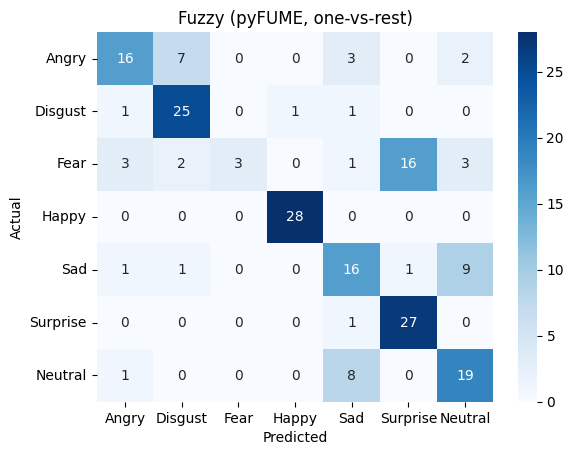

[{'model': 'Fuzzy (pyFUME, one-vs-rest)',
  'acc': 0.6836734693877551,
  'bal_acc': 0.6836734693877552,
  'macro_f1': 0.6477614683859444}]

In [69]:
from features import evaluate
from sklearn.metrics import classification_report
scores = np.array([SugenoFISTester(model=models[c], test_data=X_test, variable_names=FEATURES).predict()[0] for c in range(7)])
y_pred_fuzzy = scores.argmax(axis=0)
results = [evaluate(y_test, y_pred_fuzzy, 'Fuzzy (pyFUME, one-vs-rest)')]
results

In [70]:
from sklearn.metrics import classification_report
from features import EMOTIONS

print(classification_report(y_test, y_pred_fuzzy, labels= range(7), target_names=EMOTIONS))

              precision    recall  f1-score   support

       Angry       0.73      0.57      0.64        28
     Disgust       0.71      0.89      0.79        28
        Fear       1.00      0.11      0.19        28
       Happy       0.97      1.00      0.98        28
         Sad       0.53      0.57      0.55        28
    Surprise       0.61      0.96      0.75        28
     Neutral       0.58      0.68      0.62        28

    accuracy                           0.68       196
   macro avg       0.73      0.68      0.65       196
weighted avg       0.73      0.68      0.65       196



### 6. Save model

In [ ]:
import joblib
out_dir = Path('../results/phase_c')
out_dir.mkdir(parents=True, exist_ok=True)
joblib.dump({'models': models, 'antecedents': antecedents, 'consequents': consequents,
             'features': FEATURES}, MODELS_DIR / 'fuzzy_kdef.pkl')
df_feat.to_csv(out_dir / 'kdef_geometric_features.csv', index=False)